In [174]:
import torch

torch.cuda.empty_cache()
torch.cuda.memory_allocated()

935416320

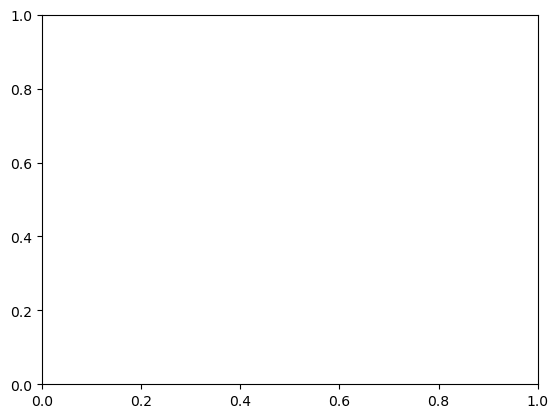

In [175]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

plt.show()

In [176]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

# Making a Custom Dataset Class

In [177]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import Compose, PILToTensor, ToDtype, Normalize
from torchvision import datasets, transforms
import os
from PIL import Image
import pandas as pd


class CustomDataset(Dataset):
    def __init__(self, csv_file, root_dir, mask_dir, transform=None, use_masks=True):
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.use_masks = use_masks

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path).convert('RGB')
        
        msk_path = os.path.join(self.mask_dir, str('img_' + str(idx) + '.png'))
        mask = Image.open(msk_path).convert('RGB')
        
        to_tensor = transforms.ToTensor()
        
        image = to_tensor(image)
        mask = to_tensor(mask)
        
        if self.use_masks:
            image = image * mask
            image[image == 0] = 0.5

        label = self.df.iloc[idx, 1]

        if self.transform:
            image = self.transform(image)

        return image, label


transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(mean=0.5, std=0.5)
])

data_train = CustomDataset(csv_file='data/train_answers.csv', root_dir='data/train_images', mask_dir='data/train_lung_masks', transform=transform, use_masks=True)

In [178]:
data_train[0][0].shape

torch.Size([1, 224, 224])

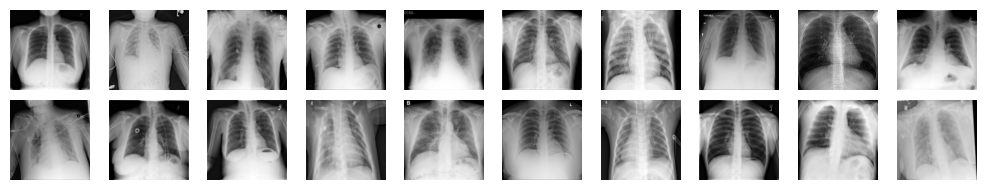

In [179]:
import torchshow as ts

x = torch.stack([data_train[i][0] * 0.5 + 0.5 for i in range(20)]).to(device)
ts.show(x, nrows=2, figsize=(10, 2))

Да рендерится через одно место, однако поверьте мне там нули где разный фон

# Simple Solution

In [180]:
import torch.nn as nn
from torchsummary import summary

class SimpleConvNet(nn.Module):
    def __init__(self):
        super(SimpleConvNet, self).__init__()

        self.conv = nn.Sequential( # in 1 256 256
            nn.Conv2d(1, 4, 9), # out 4 248 248
            nn.ReLU(),
            nn.MaxPool2d(4, 4), # out 4 62 62
            nn.Conv2d(4, 16, 9), # out 16 54 54
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # out 16 27 27
            nn.Conv2d(16, 64, 8), # out 64 20 20
            nn.ReLU(),
            nn.MaxPool2d(4, 4), # out 64 5 5
            nn.Conv2d(64, 128, 5), # out 128 1 1
            nn.Flatten() # out 128
        )
        
        self.linear = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 3) # no activation
        )
    
    def forward(self, x):
        x = self.conv(x)
        x = self.linear(x)
        return x


class SimpleUNet(nn.Module):
    def __init__(self):
        super(SimpleUNet, self).__init__()
        
        self.MaxPool = nn.MaxPool2d(2, 2) # /=2
        
        self.conv1 = nn.Sequential( # in 1 256 256
            nn.Conv2d(1, 64, 5), # out 64 252 252
            nn.ReLU(),
            nn.Conv2d(64, 64, 5), # out 64 248 248
            nn.ReLU()
        )
        # maxpool
        self.conv2 = nn.Sequential( # in 64 124 124
            nn.Conv2d(64, 128, 5), # out 128 120 120
            nn.ReLU(),
            nn.Conv2d(128, 128, 5), # out 128 116 116
            nn.ReLU()
        )
        # maxpool
        self.conv3 = nn.Sequential( # in 128 58 58
            nn.Conv2d(128, 256, 5), # out 256 54 54
            nn.ReLU(),
            nn.Conv2d(256, 256, 3), # out 256 52 52
            nn.ReLU()
        )
        # maxpool
        self.conv4 = nn.Sequential( # in 256 26 26
            nn.Conv2d(256, 512, 3), # out 512 24 24
            nn.ReLU(),
            nn.Conv2d(512, 512, 3), # out 512 22 22
            nn.ReLU()
        )
        
        self.transpose5 = nn.ConvTranspose2d(512, 256, 2, 2)
        
        self.conv5 = nn.Sequential( # in 512 44 44
            nn.Conv2d(512, 256, 5), # out 256 40 40
            nn.ReLU(),
            nn.Conv2d(256, 256, 5), # out 256 36 36
            nn.ReLU()
        )
        
        self.transpose6 = nn.ConvTranspose2d(256, 128, 2, 2)
        
        self.conv6 = nn.Sequential( # in 256 72 72
            nn.Conv2d(256, 128, 5), # out 128 68 68
            nn.ReLU(),
            nn.Conv2d(128, 128, 5), # out 128 64 64
            nn.ReLU()
        )
        
        self.transpose7 = nn.ConvTranspose2d(128, 64, 2, 2)
        
        self.conv7 = nn.Sequential( # in 128 128 128
            nn.Conv2d(128, 64, 5), # out 64 124 124
            nn.ReLU(),
            nn.Conv2d(64, 64, 5), # out 64 120 120
            nn.ReLU()
        )
        
        
        self.final = nn.Sequential( # 64 120 120
            nn.Conv2d(64, 1, 1), # out 1 120 120
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(120*120, 3)
        )
    
    def forward(self, x):
        x = self.conv1(x)
        skip7 = x[:, :, 59:187, 59:187]
        x = self.MaxPool(x)
        
        x = self.conv2(x)
        skip6 = x[:, :, 43:115, 43:115]
        x = self.MaxPool(x)
        
        x = self.conv3(x)
        skip5 = x[:, :, 3:47, 3:47]
        x = self.MaxPool(x)
        
        x = self.conv4(x)
        
        x = self.transpose5(x)
        x = torch.cat([skip5, x], dim=1)
        x = self.conv5(x)
        
        x = self.transpose6(x)
        x = torch.cat([skip6, x], dim=1)
        x = self.conv6(x)
        
        x = self.transpose7(x)
        x = torch.cat([skip7, x], dim=1)
        x = self.conv7(x)
        
        
        x = self.final(x)
        
        return x


class AlexNet(nn.Module):
    def __init__(self, num_classes: int = 3, dropout: float = 0.5) -> None:
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


model = AlexNet().to(device)
summary(model, (1, 224, 224), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 55, 55]           7,808
              ReLU-2           [-1, 64, 55, 55]               0
         MaxPool2d-3           [-1, 64, 27, 27]               0
            Conv2d-4          [-1, 192, 27, 27]         307,392
              ReLU-5          [-1, 192, 27, 27]               0
         MaxPool2d-6          [-1, 192, 13, 13]               0
            Conv2d-7          [-1, 384, 13, 13]         663,936
              ReLU-8          [-1, 384, 13, 13]               0
            Conv2d-9          [-1, 256, 13, 13]         884,992
             ReLU-10          [-1, 256, 13, 13]               0
           Conv2d-11          [-1, 256, 13, 13]         590,080
             ReLU-12          [-1, 256, 13, 13]               0
        MaxPool2d-13            [-1, 256, 6, 6]               0
AdaptiveAvgPool2d-14            [-1, 25

In [181]:
torch.cuda.memory_allocated()

1163911680

# Training Functions

In [182]:
from tqdm import tqdm
from sklearn.metrics import f1_score, recall_score, precision_score
import torch.nn.functional as F

def run_epoch(mdl, opt, loss, dataloader, is_train=True):
    mdl.train(is_train)
    total_loss = 0.0
    
    all_labels = []
    all_predictions = []
    
    with torch.set_grad_enabled(is_train):
        for x, y in tqdm(dataloader):
            x = x.to(device)
            y = y.to(device)
            
            y_pred = model(x)
            
            l = loss(y_pred, y)
            if (is_train):
                opt.zero_grad()
                l.backward()
                
                opt.step()
            
            
            total_loss += l.item() # loss
            
            correct_idx = y.detach().cpu().numpy()
            #correct_idx = np.minimum(correct_idx, 1)
            all_labels.extend(correct_idx)
            
            predicted_idx = torch.argmax(F.softmax(y_pred.detach(), dim=1), dim=1).cpu().numpy()
            #predicted_idx = np.minimum(predicted_idx, 1)
            all_predictions.extend(predicted_idx)
    
    return {"Loss": total_loss / len(dataloader.dataset), "F1": f1_score(all_labels, all_predictions, average='macro'), "Recall": recall_score(all_labels, all_predictions, average='macro'), "Precision": precision_score(all_labels, all_predictions, average='macro')}

In [183]:
import numpy as np

def subplot_metrics(metrics, title, num_epochs):
    plt.title(title)
    
    x = np.arange(len(metrics["Train"]))
    
    for lbl, hst in metrics.items():
        plt.plot(x, hst, label=lbl)
    
    plt.grid()
    plt.xticks(np.arange(num_epochs))
    plt.legend()

def plot_metrics(metrics_hist, num_epochs):
    plt.figure(figsize=(16, 8.5))
    
    plt.subplot(2, 2, 1)
    subplot_metrics(metrics_hist["Loss"], f'Loss = {metrics_hist["Loss"]["Train"][-1]}, {metrics_hist["Loss"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 2)
    subplot_metrics(metrics_hist["F1"], f'F1 = {metrics_hist["F1"]["Train"][-1]}, {metrics_hist["F1"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 3)
    subplot_metrics(metrics_hist["Recall"], f'Recall = {metrics_hist["Recall"]["Train"][-1]}, {metrics_hist["Recall"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 4)
    subplot_metrics(metrics_hist["Precision"], f'Precision = {metrics_hist["Precision"]["Train"][-1]}, {metrics_hist["Precision"]["Test"][-1]}', num_epochs)
    
    plt.subplots_adjust(wspace=0.5)
    plt.show()

In [184]:
from IPython.display import clear_output

def run_train_loop(mdl, opt, loss, train_loader, val_loader, num_epochs):
    train_hist = []
    val_hist = []
    metrics_hist = {"Loss": {"Train": [], "Test": []}, "F1":  {"Train": [], "Test": []}, "Recall":  {"Train": [], "Test": []}, "Precision":  {"Train": [], "Test": []}}
    
    for e in range(num_epochs):
        print("Trainin...")
        train_metrics = run_epoch(mdl, opt, loss, train_loader)
        for key in metrics_hist.keys():
            metrics_hist[key]["Train"].append(train_metrics[key])
        
        print("Validating...")
        val_metrics = run_epoch(mdl, opt, loss, val_loader, is_train=False)
        for key in metrics_hist.keys():
            metrics_hist[key]["Test"].append(val_metrics[key])
        
        clear_output()
        plot_metrics(metrics_hist, num_epochs)

# Train and Test Subsets

In [185]:
from torch.utils.data.dataset import random_split

num_samples = len(data_train)
num_test = int(0.2 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 21600 
 Test len: 5400


# Training

In [186]:
from torch.utils.data import DataLoader

batch_size = 128
num_epochs = 30

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(model.parameters())
criterion = torch.nn.CrossEntropyLoss()

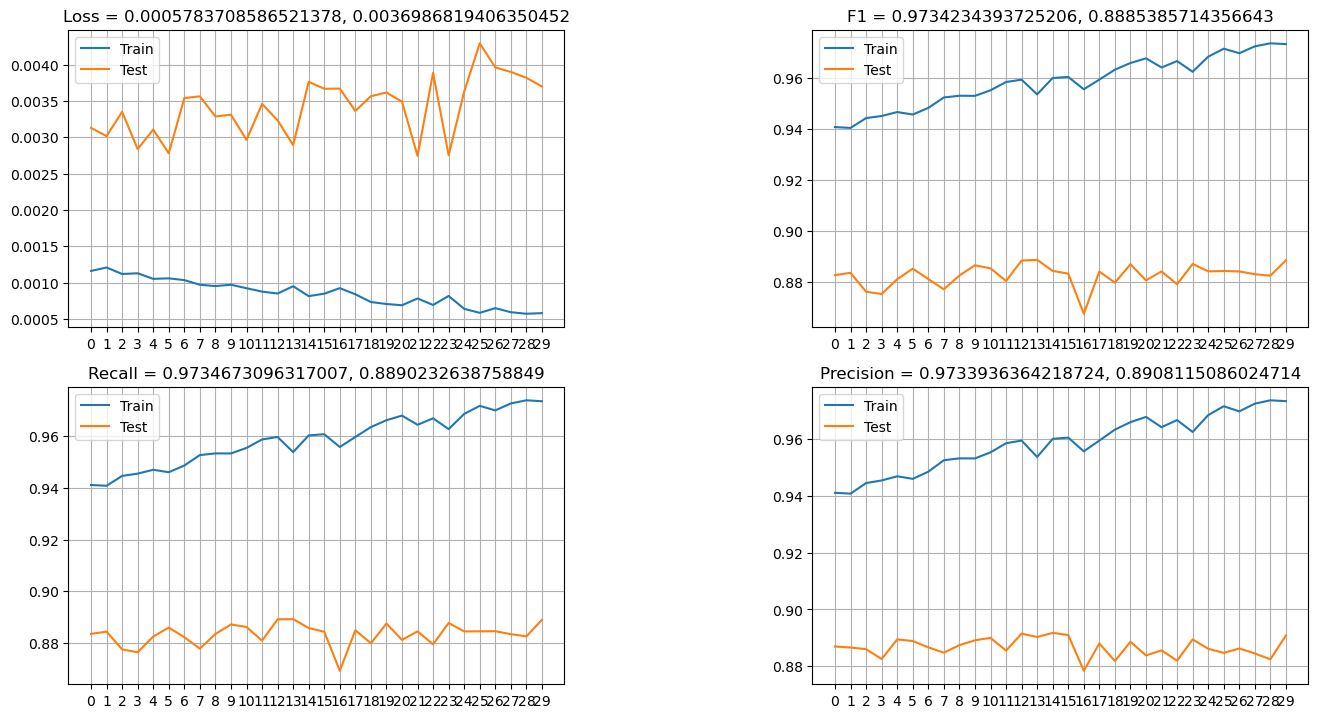

In [190]:
run_train_loop(model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

# Making the Answer Sheet

In [188]:
# transform = transforms.Compose([
#     transforms.Grayscale(),
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),           # Convert the image to a PyTorch tensor
#     transforms.Normalize(mean=0.5, std=0.5)
# ])

data_main_test = CustomDataset(csv_file='data/train_answers.csv', root_dir='data/test_images', mask_dir='data/test_lung_masks_generated', transform=transform, use_masks=True)

In [189]:
data = []

model.eval()
with torch.no_grad():
    for i in range(len(data_main_test)):
        inp = data_main_test[i][0].clone().detach()
        inp = inp.unsqueeze(0)
        inp = inp.to(device)
        
        output = model(inp)
        
        predicted_id =  torch.argmax(F.softmax(output, dim=1)).item()
        data.append([i, predicted_id])

df = pd.DataFrame(data)

file_path = 'answers.csv'

df.columns = ['id', 'target_feature']
df.to_csv(file_path, index=False, header=True)

print(f'CSV file saved to: {file_path}')

CSV file saved to: answers.csv
